# PanGenie in the 231-founder panel — benchmark

The production panel merges **78 founders genotyped from their own long-read assemblies**
(cactus) with **153 founders genotyped from short reads by PanGenie** against the
135-assembly graph. Two questions:

1. **Q1 — how much of a founder's variation does PanGenie recover** from short reads,
   compared with adding that founder's long-read assembly?
2. **Q2 — how different is the new mixed panel**, with its production QC, from the old
   GrENE-Net phase-1 SNP panel of the same 231 accessions?

**Metrics.** Against a truth genotype: **recall** = share of the variants the truth carries
that PanGenie calls; **precision** = share of PanGenie's variant calls the truth confirms;
**nRD** (non-reference discordance) = share of disagreeing genotypes among sites where either
side is non-reference. Plain genotype concordance is not reported: it is dominated by
ref/ref sites and sits above 99% whatever the quality.

**Production QC** throughout, unless marked raw: GQ < 20 → missing on the PanGenie record,
then het → missing per biallelic variant (inbred lines). All scoring is in the panel's own
**arch3 biallelic space** (each graph allele decomposed into the atomic variants on its path),
so a wrong allele in a multi-allelic bubble counts as wrong and a bubble counts once per
variant, not once per allele.

In [1]:
import os, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False})
def _root(d=None):
    d = os.path.abspath(d or os.getcwd())
    while d != os.path.dirname(d):
        if os.path.isdir(os.path.join(d, "panel", "arch3")) and os.path.isdir(os.path.join(d, "analysis")):
            return d
        d = os.path.dirname(d)
    raise RuntimeError("no kmate root above " + os.getcwd())
P = _root()
QC = f"{P}/analysis/panel_qc/pangenie_accuracy"
PLOTS = f"{P}/analysis/grenenet_selection/notebooks/plots/pangenie_accuracy"
os.makedirs(PLOTS, exist_ok=True)

CLS = ["SNP", "small", "sv_50_500", "sv_500_5k", "sv_5k"]
CLSLAB = {"SNP": "SNP", "small": "indel/MNP\n≤50 bp", "sv_50_500": "SV\n50–500 bp",
          "sv_500_5k": "SV\n0.5–5 kb", "sv_5k": "SV\n>5 kb"}
# validated categorical palettes (dataviz validate_palette.js, light surface)
CLSSHORT = {"SNP": "SNP", "small": "indel\n/MNP", "sv_50_500": "SV\n<0.5k", "sv_500_5k": "SV\n0.5–5k",
            "sv_5k": "SV\n>5k"}
FATE = {"recovered": "#2a78d6", "called_ref": "#eb6834", "no_call": "#4a3aa7",
        "skipped": "#eda100", "absent": "#e87ba4"}
FALSE = "#e34948"   # adjacent only to "recovered" across the baseline; hatched as secondary encoding
FATELAB = {"recovered": "recovered", "called_ref": "called REF", "no_call": "no call (missing after QC)",
           "skipped": "bubble skipped by PanGenie", "absent": "not in the graph"}
GRP = {"ingraph": "#2a78d6", "unseen": "#eb6834", "trueloo": "#1baf7a"}
SRC = {"cactus": "#2a78d6", "pangenie": "#eb6834"}
MISLABELLED = {"7164", "6939", "9606"}   # assembly disagrees with an independent genotyping

def panel(ax, letter, note="", y=1.02):
    ax.annotate(letter, (0, y), xycoords="axes fraction", fontweight="bold", fontsize=11,
                va="bottom", ha="left")
    if note:
        ax.annotate(note, (0.075, y), xycoords="axes fraction", fontsize=8.5,
                    va="bottom", ha="left", color="#444")

def load_scores(tag):
    fs = glob.glob(f"{QC}/scores/{tag}_*.csv")
    return pd.concat([pd.read_csv(f, dtype={"ecotype": str}) for f in fs], ignore_index=True)
ID = pd.read_csv(f"{QC}/founder_identity.csv", dtype={"ecotype": str})
VER = set(ID.loc[ID.tier == "verified", "ecotype"])                 # headline set
SENS = set(ID.loc[ID.tier.isin(["verified", "elevated"]), "ecotype"])  # sensitivity set
S_in_all, S_lo_all = load_scores("ingraph"), load_scores("trueloo")
S_lo = S_lo_all[S_lo_all.ecotype.isin(VER)]
LOO = sorted(set(S_lo.ecotype))                    # verified founders with a true leave-one-out run
S_in = S_in_all[S_in_all.ecotype.isin(LOO)]        # paired comparison on the same founders
print(ID.tier.value_counts().to_string())
print(f"\nverified founders with a true leave-one-out run: {len(LOO)} of {len(VER)}")

tier
verified     60
elevated      8
near_twin     3
mismatch      2

verified founders with a true leave-one-out run: 4 of 60


## Q1 · Which founders can be scored

Scoring short-read genotypes against a long-read assembly measures the genotyper only if
the reads and the assembly are the **same plant line**; otherwise a labelling or seed-stock
difference is charged to PanGenie. Each founder's short reads (genotyped with its own
assembly in the graph, where a true match is sharpest) are compared with **every** one of
the 135 assemblies (`reads_vs_assemblies.py`, `founder_identity.py`). The test is relative
— genotyping noise makes a sample look worse against everything, not more like another
accession — so it does not select on PanGenie's accuracy.

- **mismatch** — the reads do not match their own assembly best: different individuals.
- **near-twin** — another accession matches the reads as well as the own assembly: it stays
  in the graph when the founder is removed, so leave-one-out is not leave-one-out.
- **elevated** — own assembly is clearly the best match, but at 1.5–6× the typical
  same-individual discordance: same accession, not certainly the same plant line (the
  independent GrENE-Net genotyping mostly places one side ~5–10% off).
- **verified** — used for every accuracy number below; *verified + elevated* is reported as
  a sensitivity check.

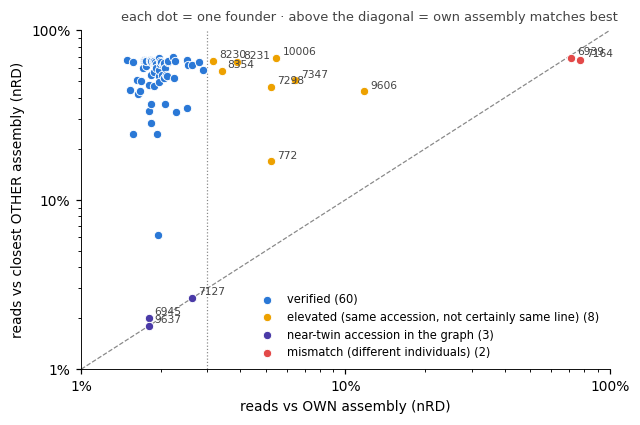

ecotype      tier  reads_vs_own best_other_name  reads_vs_best_other  reads_vs_grenenet  assembly_vs_grenenet
   8230  elevated           3.2           Tur-4                 66.3                1.6                   2.9
   8354  elevated           3.4           Kas-1                 57.8                1.5                   4.9
   8231  elevated           3.9          Sten-0                 65.1                3.0                   3.2
   7298  elevated           5.2            Bs-1                 46.4                1.2                   6.4
    772  elevated           5.2        Shahdara                 16.9                1.1                   3.3
  10006  elevated           5.5         Valsi-1                 68.6                7.1                   8.4
   7347  elevated           6.4            Ct-1                 50.6                1.0                   6.0
   9606  elevated          11.8         Toufl-1                 43.7                8.2                  10.3
   6939  m

In [2]:
TIER = {"verified": "#2a78d6", "elevated": "#eda100", "near_twin": "#4a3aa7", "mismatch": "#e34948"}
TLAB = {"verified": "verified", "elevated": "elevated (same accession, not certainly same line)",
        "near_twin": "near-twin accession in the graph", "mismatch": "mismatch (different individuals)"}
fig, ax = plt.subplots(figsize=(6.2, 4))
for t in TIER:
    d = ID[ID.tier == t]
    ax.scatter(d.reads_vs_own, d.reads_vs_best_other, s=30, color=TIER[t], linewidths=0.6,
               edgecolors="white", label=f"{TLAB[t]} ({len(d)})", zorder=3)
    for _, r in d[d.tier != "verified"].iterrows():
        ax.annotate(r.ecotype, (r.reads_vs_own, r.reads_vs_best_other), xytext=(4, 2),
                    textcoords="offset points", fontsize=7, color="#444")
lim = [0.01, 1]
ax.plot(lim, lim, ls="--", lw=0.8, color="#888")
ax.axvline(0.03, ls=":", lw=0.8, color="#888")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("reads vs OWN assembly (nRD)"); ax.set_ylabel("reads vs closest OTHER assembly (nRD)")
ax.legend(frameon=False, fontsize=7.5, loc="lower right")
panel(ax, "", "each dot = one founder · above the diagonal = own assembly matches best")
plt.savefig(f"{PLOTS}/q1_founder_identity.png", dpi=150, bbox_inches="tight"); plt.show()
print((ID[ID.tier != "verified"][["ecotype", "tier", "reads_vs_own", "best_other_name", "reads_vs_best_other",
                                 "reads_vs_grenenet", "assembly_vs_grenenet"]]
       .assign(**{c: lambda d, c=c: (100 * d[c]).round(1) for c in ["reads_vs_own", "reads_vs_best_other",
                                                                     "reads_vs_grenenet", "assembly_vs_grenenet"]})
       .to_string(index=False)))

## Q1 · What PanGenie recovers of a founder's variation

**Design.** For each assembly founder that also has public short reads, the founder's
assembly is **removed from the graph** (alleles no other assembly carries are trimmed), the
graph is re-indexed, and the founder is genotyped from its short reads — exactly the situation
of the 153 short-read founders, whose haplotypes are in no graph. Its own assembly is the
truth. (`panel/pangenie_genotyping/scripts/pangenie_trueloo_one.sh`,
`score_loo_arch3.py`.)

The earlier "leave-one-out" run genotyped the same reads against the full 135-assembly graph,
**which contains the founder's own assembly**; PanGenie then recovers the founder's own
haplotype (86% of 10002's assembly-private Chr1 alleles were called 1/1). It is shown here
only as the comparison that measures how optimistic that was.

Every variant the assembly carries ends in exactly one fate: **recovered**, **called REF**,
**no call** (missing after QC), **bubble skipped by PanGenie** (in the graph, but PanGenie's
graph builder drops bubbles containing an undefined base or within 2 k-mers of a chromosome
end — 360 of 5.2 M bubbles, few but large), or **not in the graph** (no other assembly
carries it, so no graph genotyper can call it).

The other half is what PanGenie **invents**: a **false call** is a variant PanGenie calls in
the founder where its own assembly has the reference allele. Panel A draws both on one scale
— the founder's true variants above zero, false calls below, as a % of the same true-variant
count — with the share of PanGenie's calls that are false (1 − precision) in brackets. Panel D asks
whether a stricter genotype-quality filter than production's GQ ≥ 20 would remove them, and at
what cost in true calls (PanGenie's GQ jumps from ~200 straight to its 10 000 cap, so "max"
is the only step beyond 100).

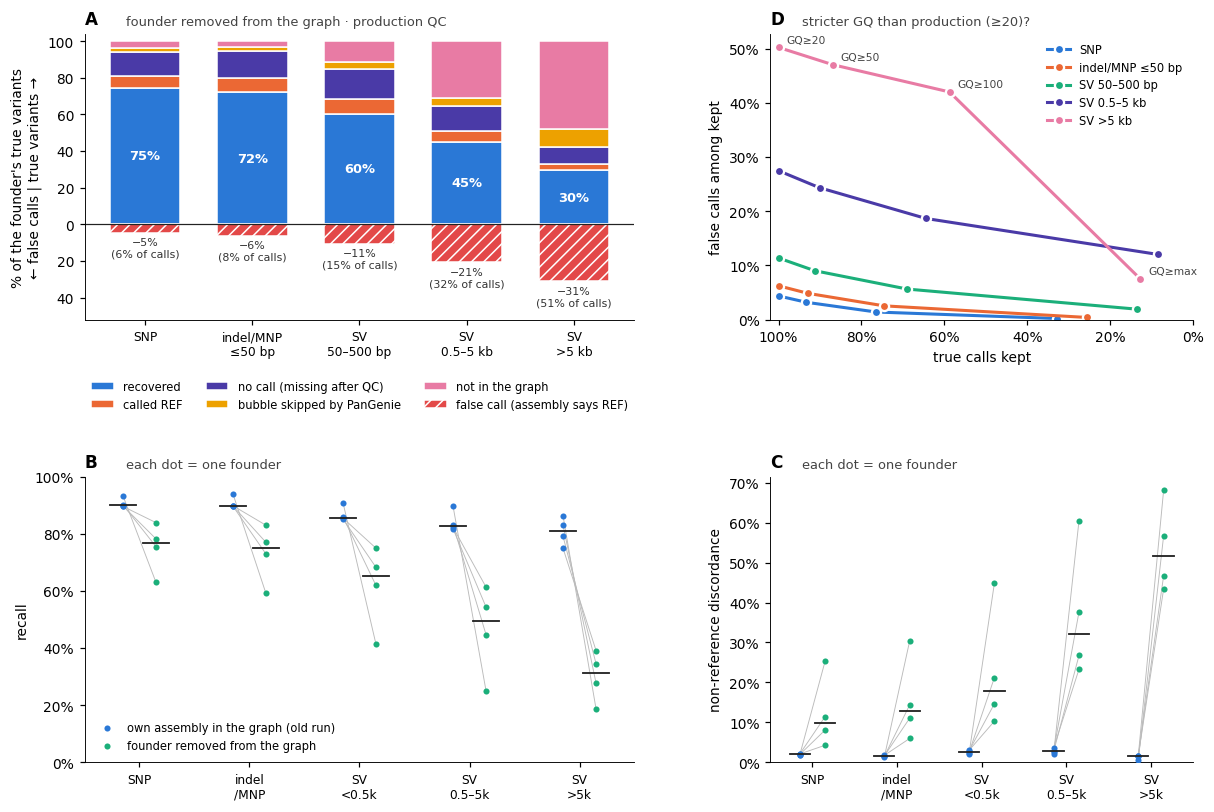

founder removed from the graph, production QC, pooled over 4 verified founders

                                           SNP  indel/MNP ≤50 bp  SV 50–500 bp  SV 0.5–5 kb  SV >5 kb
recall                                   74.56             72.21         60.41        45.14     29.54
precision                                94.21             92.18         84.91        68.44     48.75
nRD                                      12.87             16.22         23.52        37.17     53.82
% of PanGenie calls that are false        5.79              7.82         15.09        31.56     51.25
false calls per 100 true variants         4.58              6.13         10.74        20.81     31.05
% recovered                              74.56             72.21         60.41        45.14     29.54
% called REF                              6.43              7.85          7.84         5.89      3.37
% no call (missing after QC)             12.95             14.70         16.44        13.42      9.19
% 

In [3]:
def pooled(S, stage="prod"):
    g = S[S.stage == stage].groupby("size_class").sum(numeric_only=True).reindex(CLS)
    g["recall"] = g.recovered / g.truth_carriers
    g["precision"] = g.recovered / (g.recovered + g.fp)
    g["nRD"] = g.nonref_disc / g.nonref
    return g
def per_founder(S, stage="prod"):
    g = S[S.stage == stage].groupby(["ecotype", "size_class"]).sum(numeric_only=True)
    return pd.DataFrame(dict(recall=g.recovered / g.truth_carriers, nRD=g.nonref_disc / g.nonref,
                             precision=g.recovered / (g.recovered + g.fp))).reset_index()

G = pooled(S_lo)
fig = plt.figure(figsize=(13, 8.6))
gs = fig.add_gridspec(2, 2, width_ratios=[1.3, 1], hspace=0.55, wspace=0.28)
ax = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1]), fig.add_subplot(gs[0, 1])]
xx = np.arange(len(CLS)); bottom = np.zeros(len(CLS))
for f in FATE:
    v = 100 * G[f] / G.truth_carriers
    ax[0].bar(xx, v, 0.66, bottom=bottom, color=FATE[f], label=FATELAB[f],
              edgecolor="white", linewidth=1)
    bottom += v.values
fp = 100 * G.fp / G.truth_carriers                     # false calls, on the same scale
ax[0].bar(xx, -fp, 0.66, color=FALSE, hatch="///", edgecolor="white", linewidth=1,
          label="false call (assembly says REF)")
ax[0].axhline(0, color="#222", lw=0.8)
for i, (r, p, f_) in enumerate(zip(G.recall, G.precision, fp)):
    ax[0].annotate(f"{100*r:.0f}%", (i, 100*r/2), ha="center", va="center", color="white",
                   fontsize=8.5, fontweight="bold")
    ax[0].annotate(f"−{f_:.0f}%\n({100*(1-p):.0f}% of calls)", (i, -f_), xytext=(0, -3),
                   textcoords="offset points", ha="center", va="top", fontsize=7.2, color="#333")
ax[0].set_xticks(xx); ax[0].set_xticklabels([CLSLAB[c] for c in CLS], fontsize=8)
ax[0].set_ylim(-52, 104); ax[0].set_yticks(range(-40, 101, 20))
ax[0].set_yticklabels([f"{abs(v)}" for v in range(-40, 101, 20)])
ax[0].set_ylabel("% of the founder's true variants\n← false calls | true variants →")
ax[0].legend(frameon=False, fontsize=7.5, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
panel(ax[0], "A", "founder removed from the graph · production QC")

A_in, A_lo = per_founder(S_in), per_founder(S_lo)
for k, (metric, lab) in enumerate([("recall", "recall"), ("nRD", "non-reference discordance")], start=1):
    a = ax[k]
    for j, (S_, key, name) in enumerate([(A_in, "ingraph", "own assembly in the graph (old run)"),
                                         (A_lo, "trueloo", "founder removed from the graph")]):
        for i, c in enumerate(CLS):
            v = S_[S_.size_class == c][metric].values
            a.scatter(np.full(len(v), i + (j - 0.5) * 0.3), v, s=16, color=GRP[key], zorder=3,
                      linewidths=0, label=name if i == 0 else None)
            a.plot([i + (j - 0.5) * 0.3 - 0.12, i + (j - 0.5) * 0.3 + 0.12], [np.median(v)] * 2,
                   color="#222", lw=1.2, zorder=4)
    for e in LOO:                                                  # pair lines per founder
        for i, c in enumerate(CLS):
            y0 = A_in[(A_in.ecotype == e) & (A_in.size_class == c)][metric]
            y1 = A_lo[(A_lo.ecotype == e) & (A_lo.size_class == c)][metric]
            if len(y0) and len(y1):
                a.plot([i - 0.15, i + 0.15], [y0.iloc[0], y1.iloc[0]], color="#bbb", lw=0.6, zorder=2)
    a.set_xticks(xx); a.set_xticklabels([CLSSHORT[c] for c in CLS], fontsize=8)
    a.yaxis.set_major_formatter(PercentFormatter(1.0)); a.set_ylabel(lab)
    panel(a, "BC"[k - 1], "each dot = one founder")
ax[1].set_ylim(0, 1); ax[2].set_ylim(0, None)
ax[1].legend(frameon=False, fontsize=7.5, loc="lower left")
# D: can a stricter GQ remove the false calls? (hom-alt calls surviving production QC)
FC = pd.concat([pd.read_csv(f, dtype={"size_class": str}).assign(ecotype=os.path.basename(f).split(".")[0])
                for f in glob.glob(f"{QC}/false_calls/*.csv.gz")], ignore_index=True)
FC = FC[FC.ecotype.isin(LOO)]
THR = [(20, "20"), (50, "50"), (100, "100"), (10000, "max")]   # PanGenie GQ jumps from ~200 to its 10000 cap
CURVE = {"SNP": "#2a78d6", "small": "#eb6834", "sv_50_500": "#1baf7a", "sv_500_5k": "#4a3aa7", "sv_5k": "#e87ba4"}
d = ax[3]; rows = []
for c in CLS:
    x = FC[FC.size_class == c]; n_true = (x.truth == 1).sum()
    pts = [((x[x.gq >= t].truth == 1).sum() / n_true, (x[x.gq >= t].truth == 0).mean(), lab) for t, lab in THR]
    rows += [dict(size_class=c, gq=lab, kept_true=k, false=f_) for k, f_, lab in pts]
    d.plot([p[0] for p in pts], [p[1] for p in pts], "-o", color=CURVE[c], lw=2, ms=6,
           label=CLSLAB[c].replace("\n", " "), mec="white", mew=1.5)
    for k, f_, lab in pts:
        d.annotate(f"GQ≥{lab}" if c == "sv_5k" else "", (k, f_), xytext=(5, 3), textcoords="offset points",
                   fontsize=7, color="#444")
d.set_xlabel("true calls kept"); d.set_ylabel("false calls among kept")
d.xaxis.set_major_formatter(PercentFormatter(1.0)); d.yaxis.set_major_formatter(PercentFormatter(1.0))
d.set_xlim(1.02, 0); d.set_ylim(0, None); d.legend(frameon=False, fontsize=7.5, loc="upper right")
panel(d, "D", "stricter GQ than production (≥20)?")
plt.savefig(f"{PLOTS}/q1_recovery.png", dpi=150, bbox_inches="tight"); plt.show()

T = (100 * G[["recall", "precision", "nRD"]]).round(2)
T["% of PanGenie calls that are false"] = (100 * (1 - G.precision)).round(2)
T["false calls per 100 true variants"] = (100 * G.fp / G.truth_carriers).round(2)
for f in FATE:
    T[f"% {FATELAB[f]}"] = (100 * G[f] / G.truth_carriers).round(2)
T["truth variants"] = G.truth_carriers.astype(int)
T.index = [CLSLAB[c].replace("\n", " ") for c in CLS]
print(f"founder removed from the graph, production QC, pooled over {len(LOO)} verified founders\n")
print(T.T.to_string())
M = pd.concat({"old run (own assembly in graph)": per_founder(S_in).groupby("size_class")[["recall", "nRD"]].median(),
               "founder removed": per_founder(S_lo).groupby("size_class")[["recall", "nRD"]].median()}, axis=1)
print("\nmedian over founders, production QC (%)\n"); print((100 * M.reindex(CLS)).round(2).to_string())
print("\nstricter GQ, hom-alt calls surviving production QC (%): true calls kept / false among kept")
TD = pd.DataFrame(rows).assign(kept_true=lambda d: (100 * d.kept_true).round(1), false=lambda d: (100 * d.false).round(1))
print(TD.pivot(index="size_class", columns="gq", values=["kept_true", "false"]).reindex(CLS)
      [[(m, g) for m in ("kept_true", "false") for _, g in THR]].to_string())
mech = FC[FC.truth == 0].groupby("size_class").bubble_nonref.mean().reindex(CLS)
print("\nfalse calls in a bubble where the founder carries a different variant (substitution) (%)")
print((100 * mech).round(1).to_string())
SS = pooled(S_lo_all[S_lo_all.ecotype.isin(SENS)])
print(f"\nsensitivity — verified + elevated ({S_lo_all[S_lo_all.ecotype.isin(SENS)].ecotype.nunique()} founders) "
      f"vs verified ({len(LOO)}), production QC (%)")
print(pd.concat({"verified": 100 * G[["recall", "precision"]], "verified+elevated": 100 * SS[["recall", "precision"]]},
                axis=1).round(2).to_string())
R = pooled(S_lo, "raw")
print("\nraw PanGenie output (no QC), founder removed: recall / nRD (%)")
print((100 * R[["recall", "nRD"]]).round(2).T.to_string())

**Reading it.** _(filled in once the numbers are reviewed)_

### The same effect across all founders — SNPs against the GrENE-Net panel

Figure 1 rests on the founders with a true leave-one-out run. The old GrENE-Net SNP panel lets
the question be asked of **every** founder: the same PanGenie calls scored against the same
independent SNP genotypes (`grenenet_concordance_by_group.py`; biallelic SNP sites, alleles
checked, production QC).

- **own assembly in the graph** — the verified assembly founders, old run
- **founder removed** — the same founders, true leave-one-out
- **production short-read founders** — the 151 founders PanGenie genotypes for the panel;
  their haplotypes are in no graph (5772 and 9947, the two assembly founders whose
  short-read genotypes production uses, were genotyped against the full graph and are left
  out)

If having your own haplotype in the graph is what made the old run look good, the true
leave-one-out founders should fall with the production founders, not with the old run.

Panel B asks the complementary question: **variation the graph never contains.** PanGenie
only genotypes alleles some assembly already carries. For each founder, the share of its
own minor-allele SNPs in the old panel that no assembly carries: for an assembly founder
this can only be old-panel error (its haplotype is in the graph), so the assembly founders
set the floor; the excess in the short-read founders is their own variation that no graph
genotyper can recover.

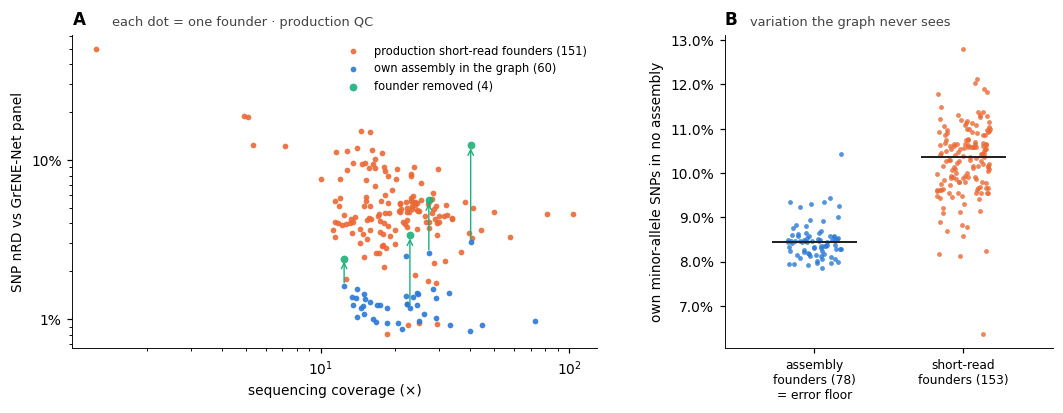

SNP nRD vs GrENE-Net, production QC — median (%) by group
group
own assembly in the graph (60)          1.31
founder removed (4)                     4.49
production short-read founders (151)    4.71

paired, same founders: own assembly in graph -> removed (%)
group  ingraph  trueloo
acc                    
10002     1.18     3.37
5784      2.61     5.61
6911      3.06    12.42
765       1.62     2.40

share of own minor-allele SNPs in no assembly (%)
            count   25%    50%    75%
source                               
cactus     7800.0  8.22   8.45   8.58
pangenie  15300.0  9.79  10.36  10.76


In [4]:
GN = pd.read_csv(f"{QC}/grenenet_concordance_by_group.csv", dtype={"acc": str})
GN = GN[GN.stage == "gq"]
st = pd.read_csv(f"{P}/preprocess_qc/output/stage_aggregate.tsv", sep="\t", dtype={"ecotype": str})
cov = st.drop_duplicates("ecotype").set_index("ecotype").cov_est
GN["cov"] = GN.acc.map(cov)
GN.loc[GN.group == "loo", "group"] = "ingraph"; GN.loc[GN.group == "main", "group"] = "unseen"
GN = GN[~((GN.group == "ingraph") & GN.acc.isin(["5772", "9947"]))]
GN = GN[(GN.group == "unseen") | GN.acc.isin(VER)]          # assembly founders: verified only
GLAB = {"ingraph": f"own assembly in the graph ({(GN.group=='ingraph').sum()})",
        "trueloo": f"founder removed ({(GN.group=='trueloo').sum()})",
        "unseen": "production short-read founders (151)"}

O = pd.read_csv(f"{QC}/old_only_snps_per_founder.csv", dtype={"founder": str})
O["frac"] = O.n_old_only_not_in_graph / O.filter(like="n_").sum(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.7), gridspec_kw=dict(width_ratios=[1.6, 1], wspace=0.3))
for g in ["unseen", "ingraph", "trueloo"]:
    d = GN[GN.group == g]
    ax[0].scatter(d["cov"], d.nRD, s=26 if g == "trueloo" else 14, color=GRP[g], linewidths=0,
                  alpha=0.9, label=GLAB[g], zorder=4 if g == "trueloo" else 3)
pair = GN[GN.group.isin(["ingraph", "trueloo"])].pivot(index="acc", columns="group", values="nRD").dropna()
for a, r in pair.iterrows():
    ax[0].annotate("", xy=(cov.get(a), r.trueloo), xytext=(cov.get(a), r.ingraph),
                   arrowprops=dict(arrowstyle="->", color="#1baf7a", lw=0.9))
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("sequencing coverage (×)"); ax[0].set_ylabel("SNP nRD vs GrENE-Net panel")
ax[0].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax[0].legend(frameon=False, fontsize=7.5, loc="upper right")
panel(ax[0], "A", "each dot = one founder · production QC")

rng = np.random.default_rng(0)
for i, s in enumerate(["cactus", "pangenie"]):
    v = O[O.source == s].frac.values
    ax[1].scatter(np.full(len(v), i) + rng.uniform(-.18, .18, len(v)), v, s=10, color=SRC[s],
                  linewidths=0, alpha=0.8)
    ax[1].plot([i - 0.28, i + 0.28], [np.median(v)] * 2, color="#222", lw=1.3)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["assembly\nfounders (78)\n= error floor",
                                                 "short-read\nfounders (153)"], fontsize=8)
ax[1].yaxis.set_major_formatter(PercentFormatter(1.0)); ax[1].set_xlim(-0.6, 1.6)
ax[1].set_ylabel("own minor-allele SNPs in no assembly")
panel(ax[1], "B", "variation the graph never sees")
plt.savefig(f"{PLOTS}/q1_all_founders.png", dpi=150, bbox_inches="tight"); plt.show()

print("SNP nRD vs GrENE-Net, production QC — median (%) by group")
print((100 * GN.groupby("group").nRD.median()).round(2).rename(GLAB).to_string())
if len(pair):
    print("\npaired, same founders: own assembly in graph -> removed (%)")
    print((100 * pair[["ingraph", "trueloo"]]).round(2).to_string())
print("\nshare of own minor-allele SNPs in no assembly (%)")
print((100 * O.groupby("source").frac.describe()[["count", "25%", "50%", "75%"]]).round(2).to_string())

**Reading it.** _(filled in once the numbers are reviewed)_

## Q2 · The new panel against the old GrENE-Net phase-1 panel

Same 231 accessions, two panels: the **old** one is a short-read SNP call set
(Beagle-imputed, no missing genotypes); the **new** one is the production arch3 panel
(78 assembly + 153 PanGenie founders; SNPs, indels and SVs; production QC; segregating
records only). SNPs are matched on position and both alleles (`panel_vs_grenenet.py`).

- **A — content.** Which old SNPs the new panel has, and what it adds. Old SNPs missing from
  the new panel are split by where they sit in the graph: *outside any graph bubble* (all 135
  assemblies agree with the reference there), *inside a bubble* (often present in the new
  panel but written as part of a longer MNP/complex record rather than as this SNP), or *in
  the graph but not segregating* among the 231 in the new panel.
- **B — genotypes.** Per founder, nRD between the two panels at shared SNPs, and the share of
  those SNPs the new panel leaves missing.
- **C — allele frequencies.** Founder allele frequency (unweighted over the 231) per shared SNP.

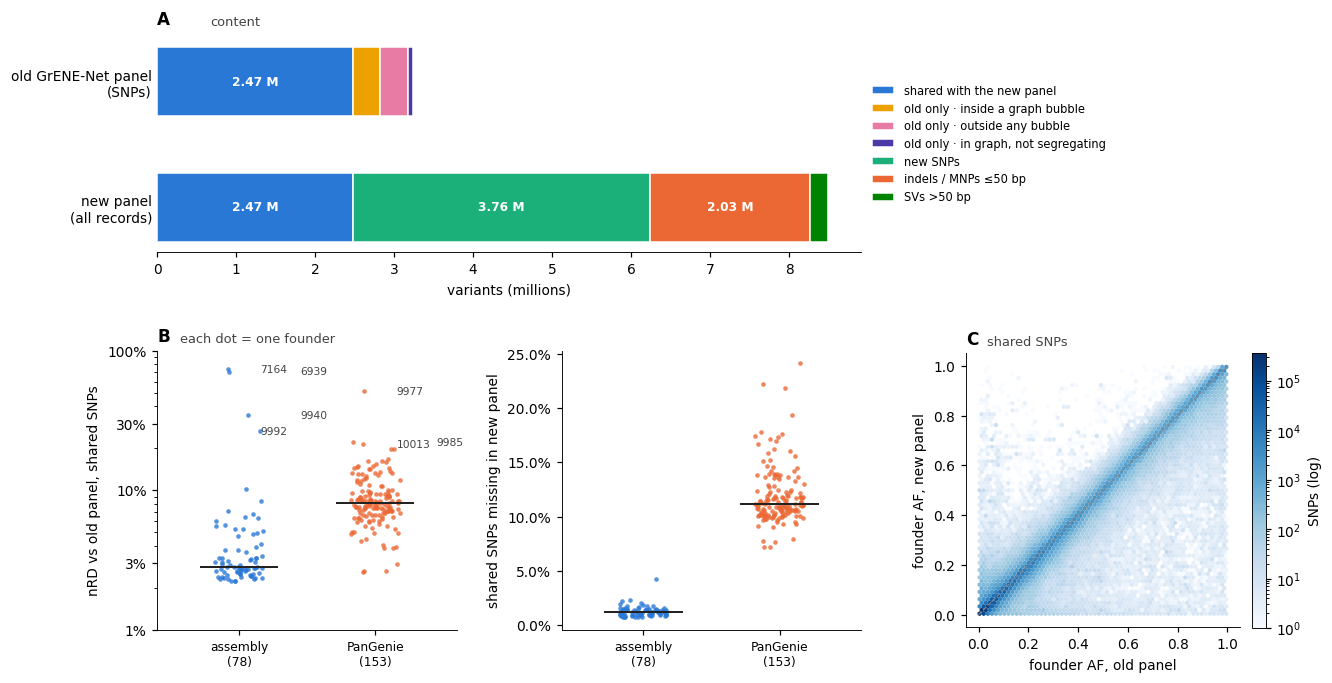

old SNPs 3,235,480: shared 2,474,199 (76.5%), old-only 761,281 [outside bubble 355,174, inside bubble 346,505, in graph not segregating 59,602]
new panel 8,489,646: SNPs 6,237,063 (new 3,762,864), indel/MNP 2,026,115, SV 226,468

per founder, shared SNPs (%) — median [IQR]
           nRD             missing_new              
          0.25  0.50  0.75        0.25   0.50   0.75
source                                              
cactus    2.58  2.84  4.09        0.97   1.21   1.44
pangenie  6.86  8.14  9.93       10.34  11.15  12.70

founder AF, 2,474,199 shared SNPs: r = 0.9850, mean |ΔAF| = 0.0122, |ΔAF| > 0.05: 4.05%, > 0.10: 1.38%


In [5]:
SITES = pd.read_csv(f"{QC}/panel_vs_grenenet_sites.csv").sum(numeric_only=True)
OB = pd.read_csv(f"{QC}/old_only_snps_bubble.csv.gz")
nb = OB[OB["cat"] == "old_only_not_in_graph"].in_bubble.value_counts()
CC = pd.read_csv(f"{QC}/panel_class_counts.csv").groupby("size_class").n.sum()
F = pd.read_csv(f"{QC}/panel_vs_grenenet_founders.csv", dtype={"founder": str})
AF = np.load(f"{QC}/panel_vs_grenenet_af.npz")

fig = plt.figure(figsize=(13, 7))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.3], hspace=0.4, wspace=0.35)
a = fig.add_subplot(gs[0, :2])
old_parts = [("shared with the new panel", SITES.shared, "#2a78d6"),
             ("old only · inside a graph bubble", nb.get(True, 0), "#eda100"),
             ("old only · outside any bubble", nb.get(False, 0), "#e87ba4"),
             ("old only · in graph, not segregating", SITES.old_only_in_graph, "#4a3aa7")]
new_parts = [("shared with the new panel", SITES.shared, "#2a78d6"),
             ("new SNPs", SITES.new_only, "#1baf7a"),
             ("indels / MNPs ≤50 bp", CC["small"], "#eb6834"),
             ("SVs >50 bp", CC[["sv_50_500", "sv_500_5k", "sv_5k"]].sum(), "#008300")]
for y, parts in [(1, old_parts), (0, new_parts)]:
    left = 0
    for lab, n, col in parts:
        a.barh(y, n / 1e6, 0.55, left=left, color=col, edgecolor="white", linewidth=1,
               label=lab if not (y == 0 and lab.startswith("shared")) else None)
        if n / 1e6 > 0.6:
            a.annotate(f"{n/1e6:.2f} M", (left + n / 2e6, y), ha="center", va="center",
                       color="white", fontsize=8, fontweight="bold")
        left += n / 1e6
a.set_yticks([1, 0]); a.set_yticklabels(["old GrENE-Net panel\n(SNPs)", "new panel\n(all records)"])
a.set_xlabel("variants (millions)"); a.spines["left"].set_visible(False); a.tick_params(axis="y", length=0)
a.legend(frameon=False, fontsize=7.5, ncol=1, loc="center left", bbox_to_anchor=(1.0, 0.5))
panel(a, "A", "content", y=1.04)

b = fig.add_subplot(gs[1, 0]); b2 = fig.add_subplot(gs[1, 1]); c = fig.add_subplot(gs[1, 2])
rng = np.random.default_rng(1)
for axx, metric, lab in [(b, "nRD", "nRD vs old panel, shared SNPs"),
                         (b2, "missing_new", "shared SNPs missing in new panel")]:
    for i, s in enumerate(["cactus", "pangenie"]):
        v = F[F.source == s][metric].values
        axx.scatter(np.full(len(v), i) + rng.uniform(-.18, .18, len(v)), v, s=9, color=SRC[s],
                    linewidths=0, alpha=0.8)
        axx.plot([i - 0.28, i + 0.28], [np.median(v)] * 2, color="#222", lw=1.3)
    axx.set_xticks([0, 1]); axx.set_xticklabels(["assembly\n(78)", "PanGenie\n(153)"], fontsize=8)
    axx.set_xlim(-0.6, 1.6); axx.yaxis.set_major_formatter(PercentFormatter(1.0)); axx.set_ylabel(lab)
b.set_yscale("log"); b.set_yticks([0.01, 0.03, 0.1, 0.3, 1]); b.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
for k, (_, r) in enumerate(F[F.nRD > 0.2].sort_values("nRD").iterrows()):   # stagger close pairs
    b.annotate(r.founder, ({"cactus": 0, "pangenie": 1}[r.source], r.nRD), xytext=(14 + 26 * (k % 2), 0),
               textcoords="offset points", fontsize=7, color="#444", va="center")
panel(b, "B", "each dot = one founder"); panel(b2, "", "")
ok = np.isfinite(AF["af_old"]) & np.isfinite(AF["af_new"])
hb = c.hexbin(AF["af_old"][ok], AF["af_new"][ok], gridsize=60, bins="log", cmap="Blues", mincnt=1,
              linewidths=0)
c.plot([0, 1], [0, 1], ls="--", lw=0.8, color="#888")
c.set_xlabel("founder AF, old panel"); c.set_ylabel("founder AF, new panel"); c.set_aspect("equal")
fig.colorbar(hb, ax=c, fraction=0.046, pad=0.04, label="SNPs (log)")
panel(c, "C", "shared SNPs")
plt.savefig(f"{PLOTS}/q2_panel_vs_grenenet.png", dpi=150, bbox_inches="tight"); plt.show()

d = np.abs(AF["af_old"][ok] - AF["af_new"][ok])
print(f"old SNPs {SITES.old_snps:,.0f}: shared {SITES.shared:,.0f} ({100*SITES.shared/SITES.old_snps:.1f}%), "
      f"old-only {SITES.old_only:,.0f} [outside bubble {nb.get(False,0):,}, inside bubble {nb.get(True,0):,}, "
      f"in graph not segregating {SITES.old_only_in_graph:,.0f}]")
print(f"new panel {CC.sum():,}: SNPs {CC['SNP']:,} (new {SITES.new_only:,.0f}), indel/MNP {CC['small']:,}, "
      f"SV {CC[['sv_50_500','sv_500_5k','sv_5k']].sum():,}")
print("\nper founder, shared SNPs (%) — median [IQR]")
q = F.groupby("source")[["nRD", "missing_new"]].quantile([.25, .5, .75]).unstack()
print((100 * q).round(2).to_string())
print(f"\nfounder AF, {ok.sum():,} shared SNPs: r = {np.corrcoef(AF['af_old'][ok], AF['af_new'][ok])[0,1]:.4f}, "
      f"mean |ΔAF| = {d.mean():.4f}, |ΔAF| > 0.05: {100*(d>0.05).mean():.2f}%, > 0.10: {100*(d>0.10).mean():.2f}%")

**Reading it.** _(filled in once the numbers are reviewed)_